In [2]:
%load_ext autoreload
%autoreload 2
%aimport
%matplotlib inline

Modules to reload:
all-except-skipped

Modules to skip:



In [3]:
import os
import sys
nb_dir = os.path.dirname(os.path.split(os.getcwd())[0])
if nb_dir not in sys.path:
    sys.path.append(nb_dir)

In [4]:
from tqdm import tqdm_notebook as tqdm
import pandas as pd
from turicreate import SFrame, load_sframe
from pathlib import Path
import turicreate.aggregate as agg
import numpy as np

In [112]:
diseases_id= load_sframe("Data/diseases_list.csv")
# disease_names = pd.read_csv("Data/disease_names.csv")

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_list.csv

Parsing completed. Parsed 100 lines in 0.056199 secs.

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[str,str,str,str,str,str,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/diseases_list.csv

Parsing completed. Parsed 332 lines in 0.020469 secs.

In [6]:
from ScienceDynamics.datasets.sjr import SJR
from ScienceDynamics.config.configs import DATASETS_SJR_DIR

In [7]:
sjr = SJR(DATASETS_SJR_DIR)
sjr_sf = sjr.data

In [8]:
sjr_sf["SJR"] = sjr_sf["SJR"].apply(lambda x: x.replace(",","."))
sjr_sf["SJR"] = sjr_sf["SJR"].apply(lambda x: x if x else "-1")
sjr_sf["SJR"] = sjr_sf["SJR"].astype(float)

Using default 12 lambda workers.

To maximize the degree of parallelism, add the following code to the beginning of the program:

"turicreate.config.set_runtime_config('TURI_DEFAULT_NUM_PYLAMBDA_WORKERS', 24)"

Note that increasing the degree of parallelism also increases the memory footprint.

In [9]:
sjr_sf
sjr_sf.groupby(["Year"],{"SJR":agg.SUM("SJR"), "Total":agg.SUM("Total Docs.")})

Year,SJR,Total
2012,19039.828030720353,3277917
2015,20974.787020750344,3409507
2000,10455.830992259085,1664477
2010,15964.50600605458,2943357
2017,22524.58598177135,3447304
2003,11811.18100631237,1935228
1999,10475.62001568079,1569469
2001,10356.27100174129,1786799
2006,12672.369017720222,2424901
2005,11874.933006122708,2295999


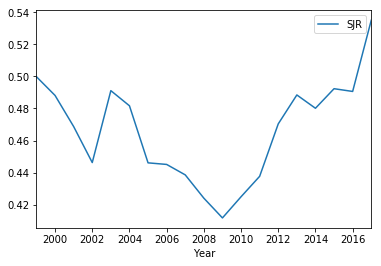

In [28]:
sjr_sf.groupby(["Year"],{"SJR":agg.MEAN("SJR")}).sort("Year").to_dataframe().plot(x="Year",y="SJR")

## Draw Graphs

In [13]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import math
import glob
import ntpath
from tqdm import tqdm
from PIL import Image
from PIL import ImageFont
from PIL import ImageDraw

In [14]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr, diseases_id, data_field="pubdate"):
    for data in sf_corr.groupby("id"):
        if len(data[1]) >5:
            yield diseases_id[diseases_id["id"]==data[0]][0]["diseases"].title(), data[1].sort_values(data_field)

### To PDF

In [15]:
def create_pdf(temp_path,pdf_name):
    # imagelist is the list with all image filenames
    res = []
    image_list = glob.glob(os.path.join(temp_path, f"*.png"))
    image_list.sort()
    for image_path in image_list:
        img = Image.open(image_path).convert("RGB")
        res.append(img)
        os.remove(image_path)

    res[0].save(f"{pdf_name}.pdf", "PDF", resolution=100.0, save_all=True, append_images=res[1:], quality=60, optimize=True)


def draw_probas_graph(graphs, output_name, output_folder, y_fields, time_field):
    rows = math.ceil(math.sqrt(len(graphs)))
    
    fig, axs = plt.subplots(rows, rows, figsize=(14, 14))
    fig.subplots_adjust(left=0.08, right=0.98, wspace=0.3, hspace=0.3)
    titles = [t for t, _ in graphs]
    graphs = [g for _, g in graphs]
    try:
        axs = axs.flatten()
    except:
        axs = [axs]
    for title, data, ax in zip(titles, graphs, axs):

        x = data[time_field]
        for  l, y in y_fields.items():
            if not data[y].isnull().values.all():
                y = np.log(data[y])
                ax.plot(x, y ,linewidth=4  ,label=l)

        ax.xaxis.set_major_locator(plt.MaxNLocator(7, integer=True))
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        # plt.title(subreddit)
        # plt.ylabel('Average edge strength')
        # plt.xlabel('Graph number')
    plt.savefig(f'{output_folder}/{output_name}.png')
    plt.clf()

## Microsoft Academics

In [ ]:
diseases_mag = load_sframe("diseases_mag.sframe")

In [ ]:
def join_pubs_promed(diseases_mag, diseases_id, diseases_occurrences):
    diseases_pub_count = diseases_mag.groupby(["disease","Paper publish year"], {"Number of papers": agg.COUNT()})
    diseases_pub_count_min_5 = diseases_mag[diseases_mag["Ref Number"] > 5].groupby(["disease","Paper publish year"], {"Number of papers (Ref >5)": agg.COUNT()})
    g = diseases_pub_count.join(diseases_pub_count_min_5)
    sf_corr = g.join(diseases_id)
    sf_corr = sf_corr.groupby(["id","Paper publish year"], {"Number of papers":agg.SUM("Number of papers"), "Number of papers (Ref >5)":agg.SUM("Number of papers (Ref >5)")})
    return sf_corr.join(diseases_occurrences, on={"id":"id","Paper publish year":"year"}).to_dataframe()

## Pubmed

In [8]:
diseases_pubmed = load_sframe("Data/pubmed/diseases_pubmed.sframe")

### Journals Current State

In [9]:
diseases_pubmed["ISSN"] = diseases_pubmed["issn_linking"].apply(lambda x: x.replace("-", ""))

In [32]:
pubmed_sjr = sjr_sf.join(diseases_pubmed, on={"ISSN":"ISSN","Year":"year"})

In [33]:
import re
pubmed_sjr["Categories Clean"] = pubmed_sjr["Categories"].apply(lambda x: re.compile(r"\s\(.*?\);{0,1}").split(x)[:-1])

In [34]:
journal_disease = pubmed_sjr.groupby(["ISSN","id","Year"], operations={"Count": agg.COUNT_DISTINCT("Normalized paper title")})

In [35]:
journal_map = pubmed_sjr[["SJR" ,"Title", "ISSN","Year"]].unique()

In [36]:
journal_disease = journal_disease.join(journal_map,["ISSN","Year"])

In [37]:
journal_disease = journal_disease[journal_disease["SJR"]>0]

In [38]:
journal_disease.filter_by(2017,"Year").sort("SJR",False)

ISSN,Year,id,Count,SJR,Title
00079235,2017,36,1,61.7859992980957,CA - A Cancer Journal forClinicians ...
14741733,2017,2,1,28.785999298095703,Nature Reviews Immunology
14741733,2017,22,1,28.785999298095703,Nature Reviews Immunology
14741733,2017,36,1,28.785999298095703,Nature Reviews Immunology
14741733,2017,12,1,28.785999298095703,Nature Reviews Immunology
14741733,2017,27,1,28.785999298095703,Nature Reviews Immunology
00928674,2017,12,1,25.136999130249023,Cell
00928674,2017,21,1,25.136999130249023,Cell
00928674,2017,11,1,25.136999130249023,Cell
00928674,2017,3,6,25.136999130249023,Cell


In [39]:
journal_disease_df = journal_disease.to_dataframe()

### Popular Journals

In [40]:
popular_journals = journal_disease.groupby("ISSN", operations={"Title":agg.SELECT_ONE("Title"), "Count": agg.SUM("Count")})

In [41]:
popular_journals.sort("Count", False)

ISSN,Title,Count
19326203,PLoS ONE,11620
02699370,AIDS,7560
15254135,Journal of AcquiredImmune Deficiency ...,5247
00221899,Journal of InfectiousDiseases ...,5199
10584838,Clinical InfectiousDiseases ...,4946
10273719,International Journal ofTuberculosis and Lung ...,3933
00951137,Journal of ClinicalMicrobiology ...,3781
00219258,Journal of BiologicalChemistry ...,3471
00199567,Infection and Immunity,3199
00029637,American Journal ofTropical Medicine and ...,3112


In [42]:
journal_disease[journal_disease["ISSN"]=="00219193"].sort("Count",False)

ISSN,Year,id,Count,SJR,Title
00219193,1999,6,182,2.687999963760376,Journal of Bacteriology
00219193,2000,6,158,2.4690001010894775,Journal of Bacteriology
00219193,2002,6,149,2.5220000743865967,Journal of Bacteriology
00219193,2001,6,149,2.6610000133514404,Journal of Bacteriology
00219193,2003,6,143,2.7100000381469727,Journal of Bacteriology
00219193,2004,6,142,2.496999979019165,Journal of Bacteriology
00219193,2005,6,137,2.6600000858306885,Journal of Bacteriology
00219193,2007,6,135,2.6530001163482666,Journal of Bacteriology
00219193,2006,6,130,2.6649999618530273,Journal of Bacteriology
00219193,2008,6,110,2.6389999389648438,Journal of Bacteriology


In [43]:
popular_journals.sort("Count", False).save("output/popular_journals.csv")

### Top Journals by Publications

In [68]:
piv_df = journal_disease_df[journal_disease_df["Year"]==2017][["ISSN","SJR"]]

In [69]:
top_10 = piv_df.drop_duplicates().sort_values("SJR",ascending=False)[:10]["ISSN"]

In [77]:
len(set(journal_disease_df["id"]))

38

In [78]:
sjr_top_journals  = journal_disease_df[(journal_disease_df["Year"]==2017)& (journal_disease_df["ISSN"].isin(top_10))].pivot_table(columns="Title",index="id",values="Count")

In [83]:
d_map = diseases_id.groupby("id",{"diseases": agg.SELECT_ONE("diseases")}).to_dataframe()

In [85]:
d_map.index = d_map.id

In [90]:
sjr_top_journals = d_map.join(sjr_top_journals)

In [91]:
sjr_top_journals = sjr_top_journals.fillna(0)

In [94]:
disease_names = pd.read_csv("Data/disease_names.csv")

In [100]:
sjr_top_journals.merge(disease_names, right_on="id",left_index=True).to_csv("output/sjr-top-journals.csv")

In [105]:
journal_disease_sf = SFrame(journal_disease_df)

In [107]:
journal_disease_sf["Score"] = journal_disease_sf["Count"]*journal_disease_sf["SJR"]

In [111]:
journal_disease_score = journal_disease_sf.groupby("id",{"Count":agg.SUM("Count"), "Score":agg.SUM("Score")})

In [113]:
journal_disease_score["JScore"] = journal_disease_score["Score"] /journal_disease_score["Count"] 

In [117]:
journal_disease_score = journal_disease_score.join(SFrame(disease_names),{"id":"id"})

In [120]:
journal_disease_score.sort("JScore",False)

id,Count,Score,JScore,Disease
2,70809,210784.82508722693,2.9768083871715025,Ebola
3,52684,143021.78603085876,2.714710083343306,Zika virus
6,1471225,3456688.40068081,2.349530765641428,Diarrheal diseases
26,33419,75354.23998149484,2.2548322804840013,Yellow fever
32,560610,1185179.9752114564,2.114089964880142,Malaria
35,288182,597600.0055451766,2.0736895626554626,Genital herpes
34,76756,158089.47703380138,2.059636732422239,Diphtheria
14,31013,63047.643059410155,2.0329424131625498,Gonococcal infection
5,24875,50058.391915626824,2.012397664949822,Trachoma
1,5867,11794.844988569617,2.010370715624615,Guinea worm disease


In [127]:
journal_disease_year_score = journal_disease_sf.groupby(["id","Year"],{"Count":agg.SUM("Count"), "Score":agg.SUM("Score")})

In [128]:
journal_disease_year_score["JScore"] = journal_disease_year_score["Score"] /journal_disease_year_score["Count"] 

In [129]:
journal_disease_year_score = journal_disease_year_score.join(SFrame(disease_names),{"id":"id"})

In [170]:
journal_disease_year_score.filter_by(2017, "Year").sort("JScore",True)

Year,id,Count,Score,JScore,Disease
2017,23,2961,2516.8649968504906,0.8500050647924656,Cystic echinococcosis
2017,25,661,721.0150017738342,1.090794253818206,Trichomoniasis
2017,29,94,109.78400008380413,1.1679148945085547,Trichuriasis
2017,17,7201,8729.19997239858,1.212220521094095,Otitis media
2017,38,1819,2273.4319938644767,1.2498251752965788,Cysticercosis
2017,37,562,740.555997043848,1.3177152972310464,Typhoid and paratyphoid
2017,11,8627,11790.228061765432,1.3666660556120822,Leprosy
2017,15,2974,4433.485980503261,1.490748480330619,Ascariasis
2017,7,9522,14336.49600314349,1.5056181477781443,Leishmaniasis
2017,9,6427,9835.631009556353,1.5303611342082393,Schistosomiasis


In [172]:
journal_disease_year_score.save("output/journal_disease_year_score.csv","csv")

In [135]:
journal_disease_year_score = journal_disease_year_score.sort(["Disease", "Year"])

In [143]:
journal_disease_year_score["Year"].min()

1999

In [173]:
journal_disease_year_score

Year,id,Count,Score,JScore,Disease
1999,36,70756,79816.62185105681,1.1280544667739387,Acute hepatitis
2000,36,72121,89592.29928989708,1.2422498203005654,Acute hepatitis
2001,36,73095,89178.37603375316,1.2200338741877441,Acute hepatitis
2002,36,74683,92847.40662319958,1.2432200985927129,Acute hepatitis
2003,36,75452,96959.36673939228,1.2850470065656614,Acute hepatitis
2004,36,75797,104258.01921143383,1.3754900485696508,Acute hepatitis
2005,36,76215,108955.6703747809,1.429583026632302,Acute hepatitis
2006,36,76693,119428.90670817345,1.5572334725225698,Acute hepatitis
2007,36,78523,123289.02477440238,1.5701007956191482,Acute hepatitis
2008,36,78804,132116.02284563333,1.676514172448522,Acute hepatitis


In [198]:
for k,v in journal_disease_year_score.to_dataframe().groupby("Disease"):
    v[["Year","JScore"]].to_csv(f"output/reg/{k.replace('/','-')}.csv", index=False)

In [200]:
!zip -r output/reg.zip output/reg/

  adding: output/reg/ (stored 0%)
  adding: output/reg/Acute hepatitis.csv (deflated 48%)
  adding: output/reg/African trypanosomiasis.csv (deflated 48%)
  adding: output/reg/Ascariasis.csv (deflated 48%)
  adding: output/reg/Chagas disease.csv (deflated 48%)
  adding: output/reg/Chlamydial infection.csv (deflated 48%)
  adding: output/reg/Cystic echinococcosis.csv (deflated 48%)
  adding: output/reg/Cysticercosis.csv (deflated 48%)
  adding: output/reg/Dengue.csv (deflated 49%)
  adding: output/reg/Diarrheal diseases.csv (deflated 49%)
  adding: output/reg/Diphtheria.csv (deflated 48%)
  adding: output/reg/Ebola.csv (deflated 48%)
  adding: output/reg/Encephalitis.csv (deflated 48%)
  adding: output/reg/Genital herpes.csv (deflated 47%)
  adding: output/reg/Gonococcal infection.csv (deflated 48%)
  adding: output/reg/Guinea worm disease.csv (deflated 47%)
  adding: output/reg/HIV-AIDS.csv (deflated 48%)
  adding: output/reg/Hookworm disease.csv (deflated 47%)
  adding: output/reg/Inva

In [163]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [149]:
dframe = journal_disease_year_score.to_dataframe()

In [151]:
dframe = dframe[dframe["id"]==32]

In [164]:
def func(x, a, b, c):
    return a * np.exp(-b * x) + c

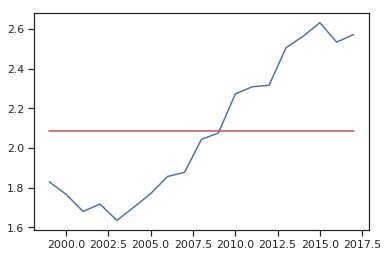

In [169]:
popt, pcov = curve_fit(func, dframe["Year"], dframe["JScore"])

plt.plot(dframe["Year"], dframe["JScore"], 'b-', label='data')

plt.plot(dframe["Year"], func(dframe["Year"], *popt), 'r-',
         label='fit: a=%5.3f, b=%5.3f, c=%5.3f' % tuple(popt))

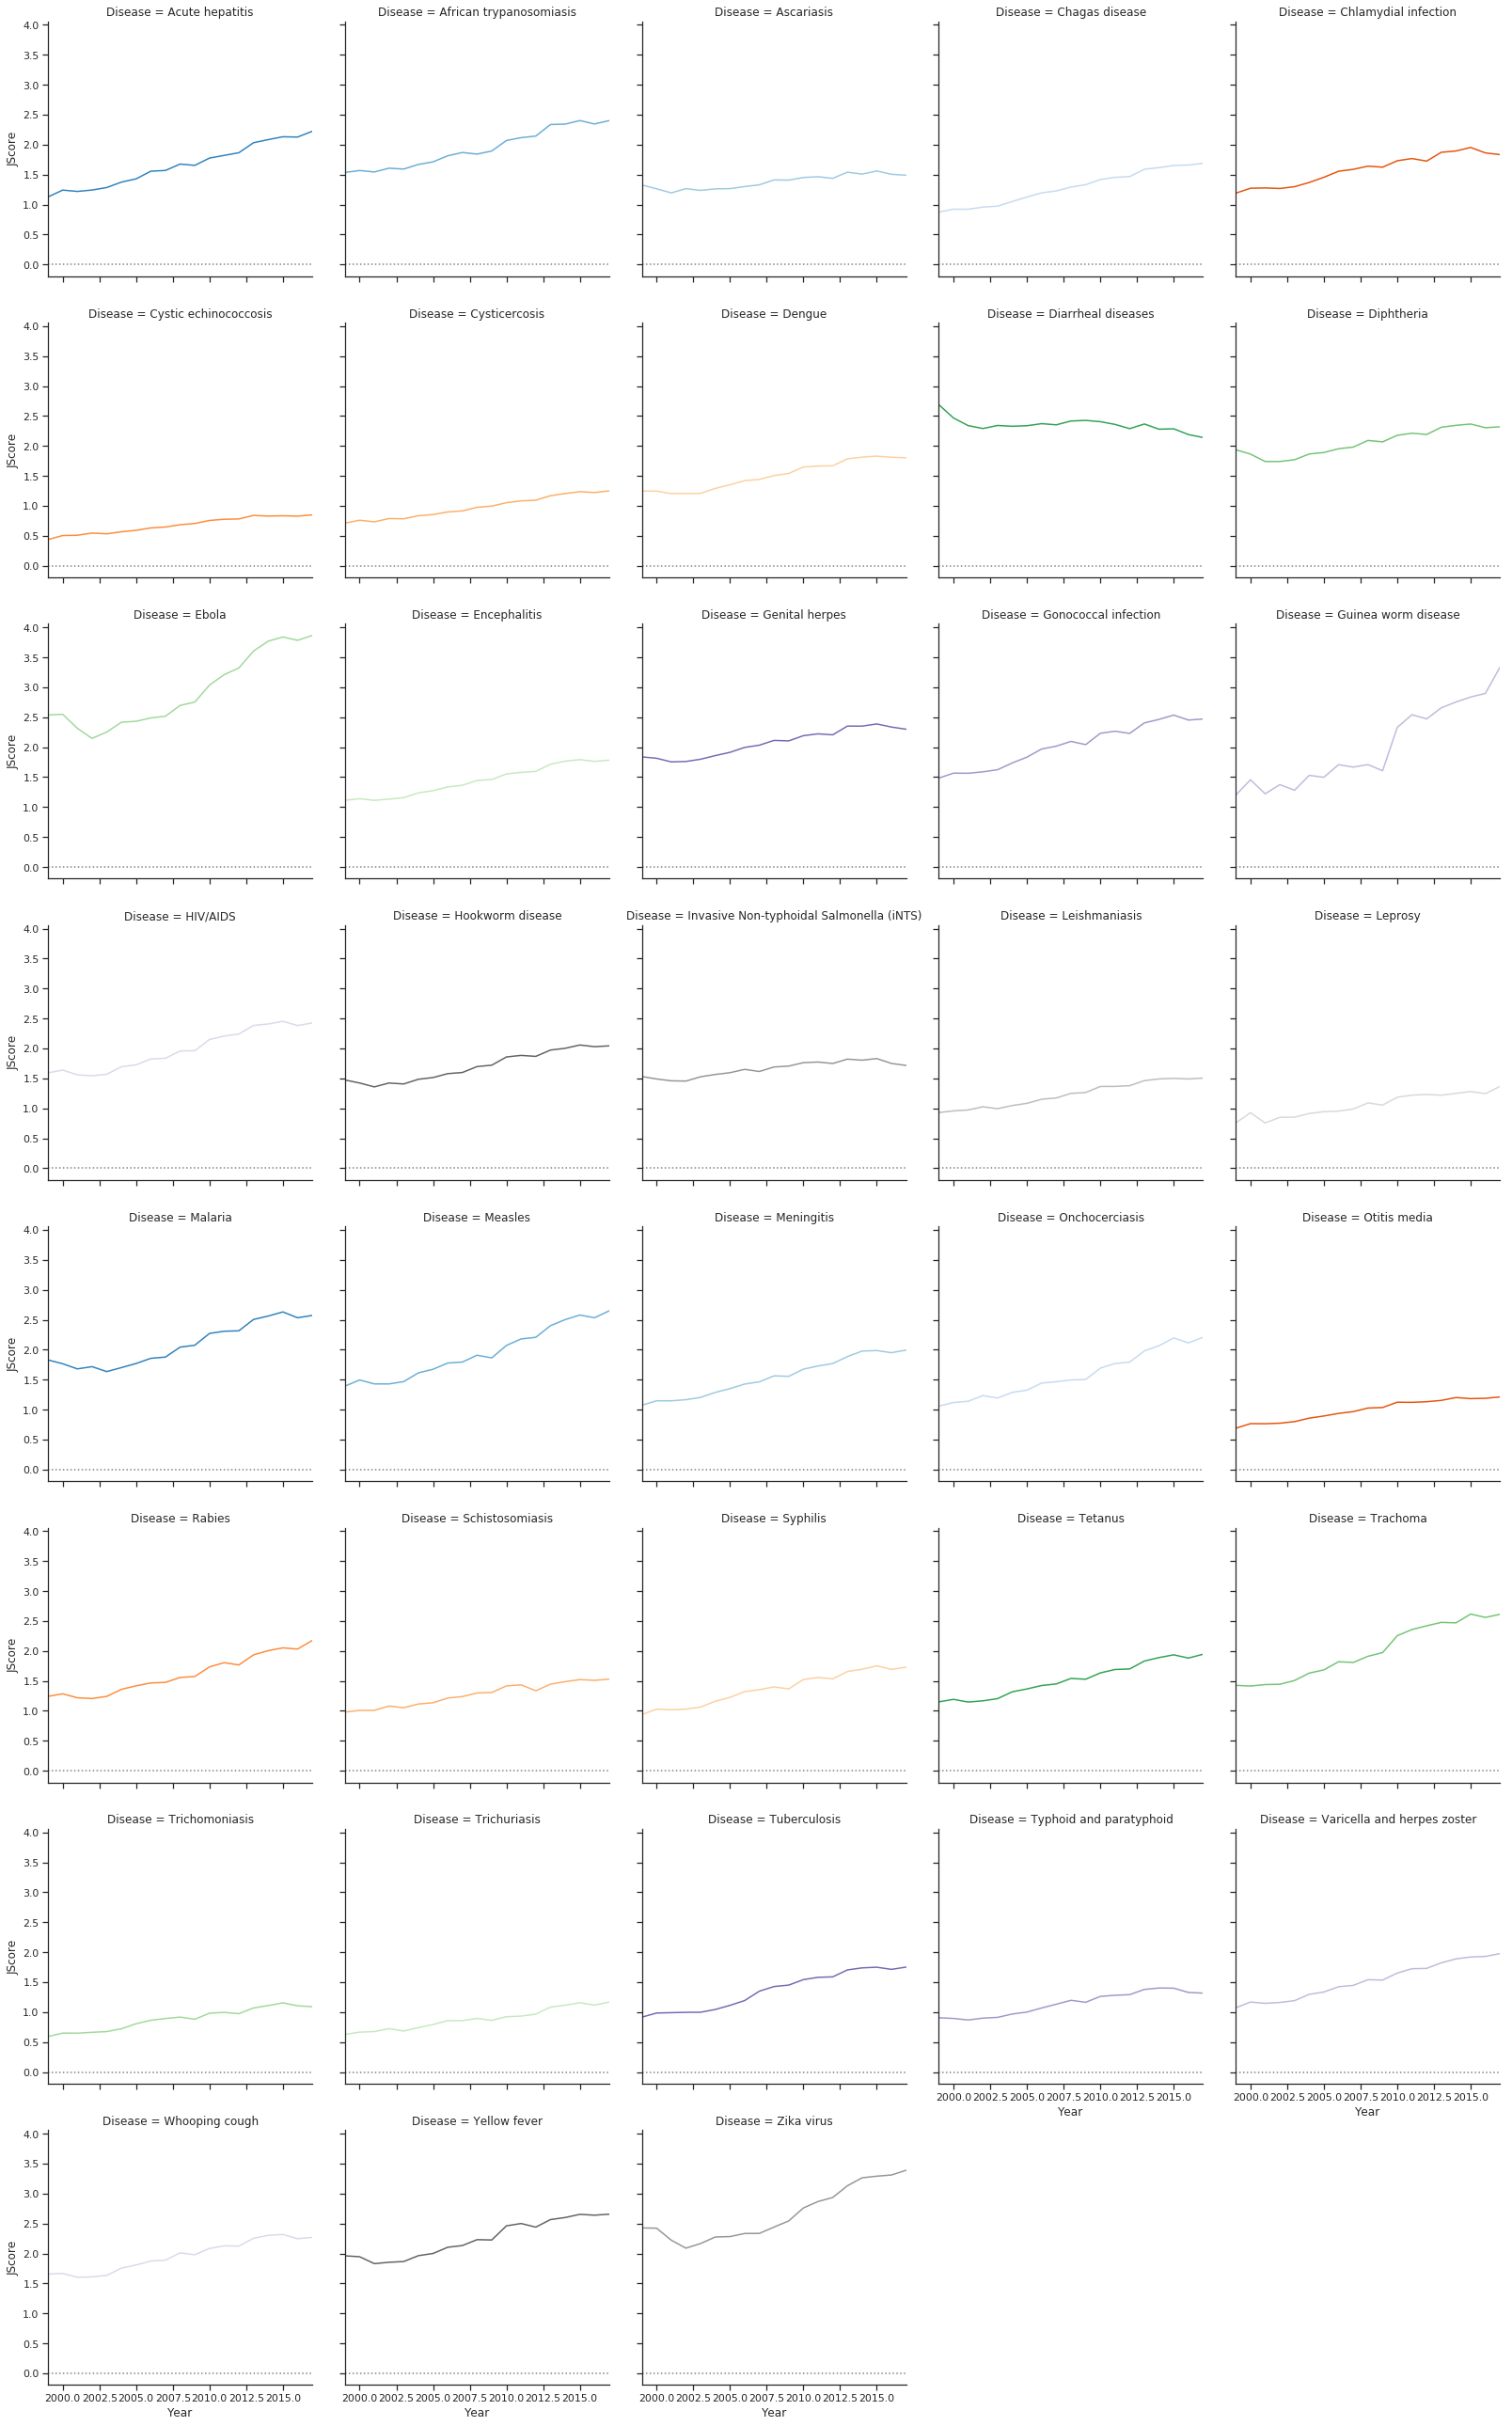

In [145]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(journal_disease_year_score.to_dataframe(), col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 )

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "JScore")

# Adjust the tick positions and labels
grid.set(xlim=(1999, 2017))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

In [75]:
len(diseases_pubmed[diseases_pubmed["id"]==1])

407

## Aminer

In [5]:
diseases_miner = load_sframe("Data/aminer/diseases_aminer.sframe")
diseases_miner["year"] = diseases_miner["year"].astype(int)

### Top Papers by Venue

In [38]:
top_papers = diseases_miner.groupby("id", operations={"Citations": agg.MAX("n_citation"), "venue":agg.ARGMAX("n_citation","venue"), "title":agg.ARGMAX("n_citation","title")})

In [39]:
top_papers = top_papers.unpack("venue")

In [40]:
top_papers.join(diseases_id.groupby("id", operations=agg.SELECT_ONE("diseases")),on={"id":"id"})

id,Citations,title,venue.id,venue.raw
15,1852.0,"Soil-transmitted helminthinfections: ascariasis, ...",None,"Lancet (London, England)"
35,1697.0,The Complete DNA Sequenceof the Long Unique Re ...,None,The Journal of generalvirology ...
12,5689.0,Prevention of HIV-1infection with early ...,None,The New England journalof medicine ...
6,7780.0,The Complete GenomeSequence of Escherichia ...,None,science
5,1240.0,Effects of improved watersupply and sanitation on ...,5451a5c4e0cf0b02b5f38488,Bulletin of the WorldHealth Organization ...
16,1699.0,Tetanus and botulinum-Bneurotoxins block ...,5451a57ae0cf0b02b5f2dd9f,Nature
7,2759.0,Leishmaniasis worldwideand global estimates of ...,5451a5c4e0cf0b02b5f389cd,PloS one
26,935.0,Nucleotide sequence ofyellow fever virus: ...,None,science
14,640.0,Prevalence of Chlamydialand Gonococcal Infect ...,None,None
0,1282.0,"The Genome Sequence ofTrypanosoma cruzi, ...",None,"Science (New York, N.Y.)"


### Disease Citaion Year

In [41]:
citations_year = diseases_miner.groupby(["year"], operations={"Total Citaions": agg.SUM("n_citation")})

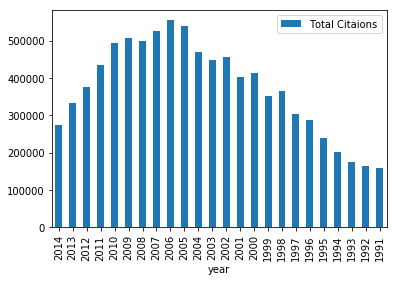

In [42]:
citations_year[(citations_year["year"]>1990)& (citations_year["year"]<2015)].sort("year",False).to_dataframe().plot(kind="bar",x="year")

In [43]:
disease_citations_year = diseases_miner.groupby(["id","year"], operations={"Citaions": agg.SUM("n_citation"),"Average Citaions": agg.AVG("n_citation")})

In [44]:
disease_citations_year = disease_citations_year.join(citations_year)

In [45]:
disease_citations_year["Ciations Norm"] = disease_citations_year["Citaions"]/disease_citations_year["Total Citaions"]

In [46]:
disease_citations_year

id,year,Citaions,Average Citaions,Total Citaions,Ciations Norm
26,1863,0.0,0.0,1.0,0.0
32,1948,37.0,0.13653136531365315,251.0,0.14741035856573706
37,1918,2.0,0.10526315789473684,86.0,0.023255813953488372
4,1939,0.0,0.0,201.0,0.0
34,1890,1.0,0.02941176470588236,10.0,0.1
27,1888,0.0,0.0,13.0,0.0
17,2019,0.0,0.0,0.0,nan
2,2004,2850.0,29.687500000000018,469858.0,0.00606566239161619
22,1860,0.0,0.0,1.0,0.0
23,1956,1.0,0.02631578947368421,1659.0,0.0006027727546714888


In [47]:
output_folder = "output"
temp_folder = "temp"

os.makedirs(output_folder, exist_ok=True)
des = list(get_d(disease_citations_year.to_dataframe(), diseases_id, "year"))
for i, curr_f in enumerate(tqdm(chunks(des, 9), total=((len(des) // 9)+1))):
    draw_probas_graph(curr_f, str(i), temp_folder,{"Average Citaions":"Average Citaions","Ciations Norm":"Ciations Norm"}, "year")
create_pdf(temp_folder,f"{output_folder}/disease_citations_year2")

100%|██████████| 5/5 [00:05<00:00,  1.04s/it]


<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

### Add Citaion by Year (Calculate how many citaions added a year)

In [48]:
diseases_miner

abstract,authors,doi,pub_id,isbn
Using the total RNAextracted from ConA ...,"[{'name': 'TONG Tie-gang', 'org': 'National ...",None,53e9b732b7602d97042c9bd5,None
None,"[{'name': 'S. A. HERZOG','id': '53f432a7dabfae ...",10.1017/S0950268810001664,53e9b732b7602d97042c9c28,None
Objective To study thechange in Th1/Th2 ...,"[{'name': 'ZHU Bin','org': 'The infectious ...",None,53e9b732b7602d97042c9c33,None
None,"[{'name': 'Pamina M.Gorbach', 'id': '53f4 ...",10.1097/00002030-200216004-00006 ...,53e9b732b7602d97042c9c4b,None
We have previouslydemonstrated that ...,"[{'name': 'N Enomoto','id': '53f80937dabfae ...",10.1172/JCI118025,53e9b732b7602d97042c9c90,None
None,"[{'name': 'Naresh C.Bal', 'id': '53f42c8e ...",10.1515/BC.2007.057,53e9b732b7602d97042c9c91,None
To determine whetherrewording postal remi ...,"[{'name': 'P Hawe', 'id':'53f7b2e0dabfae938c6d ...",10.1136/adc.79.2.136,53e9b732b7602d97042c9cd4,None
"Microcin 140, a novelantibiotic of low ...","[{'name': 'Antonio F.Duro', 'org': ...",10.1016/0006-291X(79)91729-7 ...,53e9b732b7602d97042c9cf4,None
None,"[{'name': 'Raymond T.Chung', 'id': '53f453 ...",10.1002/hep.22070,53e9b732b7602d97042c9e35,None
None,"[{'name': 'HideoNakamura', 'org': ...",10.1016/S1072-7515(00)00589-5 ...,53e9b732b7602d97042c9ed7,None


### General Publication/Ciation

In [12]:
pub_cite.sort("id")[-10:]

id,count,n_citation,avg_citation,Disease
28,72754,411452.0,5.6967297095229,Invasive Non-typhoidalSalmonella (iNTS) ...
29,262,2377.0,9.142307692307696,Trichuriasis
31,43647,200543.0,4.649409964528324,Encephalitis
32,75428,626459.0,8.343553134531158,Malaria
33,21128,60840.0,2.9200863930885697,Varicella and herpeszoster ...
34,13541,28373.0,2.1101442808270128,Diphtheria
35,35200,201282.0,5.812527072684788,Genital herpes
36,176778,1471180.0,8.45092914380903,Acute hepatitis
37,2590,4311.0,1.695908733280882,Typhoid and paratyphoid
38,4323,11381.0,2.6492085661080056,Cysticercosis


In [7]:
pub_cite = diseases_miner.groupby(["id"], {"count": agg.COUNT(),"n_citation": agg.SUM("n_citation"), "avg_citation": agg.AVG("n_citation")}).join(SFrame(disease_names),{"id":"id"})

In [13]:
pub_cite.save("output/pub_cite.csv","csv")

### TOP Journals By Disease 

In [49]:
diseases_miner = diseases_miner.unpack('venue')

In [62]:
top_journals = diseases_miner.groupby(["venue.raw", "id"], {"disease":agg.SELECT_ONE("disease") ,"count": agg.COUNT(),"n_citation": agg.SUM("n_citation"), "avg_citation": agg.AVG("n_citation")})

In [63]:
top_journals.dropna().sort('n_citation',ascending=False).save("output/top_journals_diseases.csv", "csv")

### TOP Journals By Ciations 

In [52]:
diseases_miner

abstract,authors,doi,pub_id,isbn
Using the total RNAextracted from ConA ...,"[{'name': 'TONG Tie-gang', 'org': 'National ...",None,53e9b732b7602d97042c9bd5,None
None,"[{'name': 'S. A. HERZOG','id': '53f432a7dabfae ...",10.1017/S0950268810001664,53e9b732b7602d97042c9c28,None
Objective To study thechange in Th1/Th2 ...,"[{'name': 'ZHU Bin','org': 'The infectious ...",None,53e9b732b7602d97042c9c33,None
None,"[{'name': 'Pamina M.Gorbach', 'id': '53f4 ...",10.1097/00002030-200216004-00006 ...,53e9b732b7602d97042c9c4b,None
We have previouslydemonstrated that ...,"[{'name': 'N Enomoto','id': '53f80937dabfae ...",10.1172/JCI118025,53e9b732b7602d97042c9c90,None
None,"[{'name': 'Naresh C.Bal', 'id': '53f42c8e ...",10.1515/BC.2007.057,53e9b732b7602d97042c9c91,None
To determine whetherrewording postal remi ...,"[{'name': 'P Hawe', 'id':'53f7b2e0dabfae938c6d ...",10.1136/adc.79.2.136,53e9b732b7602d97042c9cd4,None
"Microcin 140, a novelantibiotic of low ...","[{'name': 'Antonio F.Duro', 'org': ...",10.1016/0006-291X(79)91729-7 ...,53e9b732b7602d97042c9cf4,None
None,"[{'name': 'Raymond T.Chung', 'id': '53f453 ...",10.1002/hep.22070,53e9b732b7602d97042c9e35,None
None,"[{'name': 'HideoNakamura', 'org': ...",10.1016/S1072-7515(00)00589-5 ...,53e9b732b7602d97042c9ed7,None


In [53]:
top_citaions = diseases_miner.dropna("disease").groupby(["venue.id"], {"Venue":agg.SELECT_ONE("venue.raw"),"n_citation": agg.SUM("n_citation"), "avg_citation": agg.AVG("n_citation"),"count":agg.COUNT()})

In [57]:
top_citaions = top_citaions[(top_citaions["venue.id"]!=None) &(top_citaions["count"]> 20)]

In [60]:
top_citaions.sort('n_citation',ascending=False).save("output/popular_journals_citaions.csv","csv")

In [59]:
top_citaions.sort("avg_citation",ascending=False)

venue.id,Venue,n_citation,avg_citation,count
5451a5c5e0cf0b02b5f3976f,Molecular systems biology,10647.0,217.28571428571433,49
5451a5c5e0cf0b02b5f396cb,Cellular and molecularbiology ...,2967.0,123.625,24
5451a5c6e0cf0b02b5f39776,Nature genetics,26946.0,115.15384615384616,234
5451a5c5e0cf0b02b5f396fe,Embo Journal,11941.0,108.55454545454545,110
5451a5c4e0cf0b02b5f3930a,Annual Review ofImmunology ...,6381.0,106.35,60
5451a5c5e0cf0b02b5f39726,Genome research,8524.0,100.28235294117647,85
5451a5c4e0cf0b02b5f380b3,PLoS biology,10943.0,95.15652173913047,115
5451a5c5e0cf0b02b5f39633,Clinical microbiologyreviews ...,16308.0,79.55121951219508,205
5451a5c6e0cf0b02b5f3a35a,Journal of health andsocial behavior ...,2424.0,78.19354838709674,31
5451a5c9e0cf0b02b5f3bf99,Journal ofnanobiotechnology ...,1792.0,77.91304347826086,23


## Semantic Scholar

In [10]:
diseases_sm = load_sframe("Data/sm/diseases_sm.sframe")

In [11]:
pubmed = load_sframe("Data/pubmed/pubmed.sframe")

In [172]:
disease_names = SFrame.read_csv("Data/disease_names.csv")

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/disease_names.csv

------------------------------------------------------
Inferred types from first 100 line(s) of file as 
column_type_hints=[int,str]
If parsing fails due to incorrect types, you can correct
the inferred type list above and pass it to read_csv in
the column_type_hints argument
------------------------------------------------------


Parsing completed. Parsed 100 lines in 0.060203 secs.

Finished parsing file /storage/homedir/dima/Projects/ScienceDynamics/examples/Infectious Disease Trends/Data/disease_names.csv

Parsing completed. Parsed 334 lines in 0.020829 secs.

In [116]:
disease_names = disease_names.rename({"GIDEON":"Disease"})

In [17]:
diseases_sm = diseases_sm.join(pubmed[["issn_linking","pmid"]], {"pmid":"pmid"})

### Journals Current State

In [19]:
diseases_sm["ISSN"] = diseases_sm["issn_linking"].apply(lambda x: x.replace("-", ""))

In [21]:
pubmed_sjr = sjr_sf.join(diseases_sm, on={"ISSN":"ISSN","Year":"year"})

In [57]:
import re
pubmed_sjr["Categories Clean"] = pubmed_sjr["Categories"].apply(lambda x: re.compile(r"\s\(.*?\);{0,1}").split(x)[:-1])

In [58]:
pubmed_sjr["Categories Clean"] = pubmed_sjr["Categories Clean"].apply(lambda x: {c.strip() for c in x})

In [59]:
cat = {"Immunology", "Epidemiology", "Infectious Diseases", "Virology", "Microbiology"}

In [64]:
cat & {"Immunology"}

{'Immunology'}

In [69]:
pubmed_sjr = pubmed_sjr[pubmed_sjr["Categories Clean"].apply(lambda x: len(set(x) & cat)>0)]

In [70]:
journal_disease = pubmed_sjr.groupby(["ISSN","id","Year"], operations={"Count": agg.COUNT_DISTINCT("paper id")})

In [71]:
journal_map = pubmed_sjr[["SJR" ,"Title", "ISSN","Year"]].unique()

In [72]:
journal_disease = journal_disease.join(journal_map,["ISSN","Year"])

In [73]:
journal_disease = journal_disease[journal_disease["SJR"]>0]

In [74]:
journal_disease.filter_by(2017,"Year").sort("SJR",False)

ISSN,Year,id,Count,SJR,Title
10575987,2017,264,2,34.63800048828125,MMWR. Recommendations andreports : Morbidity and ...
14741733,2017,257,1,28.785999298095703,Nature Reviews Immunology
14741733,2017,32,1,28.785999298095703,Nature Reviews Immunology
15292908,2017,79,2,14.006999969482422,Nature Immunology
15292908,2017,92,1,14.006999969482422,Nature Immunology
15292908,2017,38,1,14.006999969482422,Nature Immunology
15292908,2017,264,2,14.006999969482422,Nature Immunology
10747613,2017,244,1,13.392999649047852,Immunity
10747613,2017,92,10,13.392999649047852,Immunity
10747613,2017,299,1,13.392999649047852,Immunity


In [75]:
journal_disease_df = journal_disease.to_dataframe()

### Popular Journals

In [76]:
popular_journals = journal_disease.groupby("ISSN", operations={"Title":agg.SELECT_ONE("Title"), "Count": agg.SUM("Count")})

In [77]:
popular_journals.sort("Count", False)

ISSN,Title,Count
10584838,Clinical InfectiousDiseases ...,5532
00221899,Journal of InfectiousDiseases ...,5286
10806040,Emerging InfectiousDiseases ...,4353
00951137,Journal of ClinicalMicrobiology ...,4295
14712334,BMC Infectious Diseases,3743
00029637,American Journal ofTropical Medicine and ...,3479
19352727,PLoS Neglected TropicalDiseases ...,3052
14752875,Malaria Journal,2925
00664804,Antimicrobial Agents andChemotherapy ...,2770
00199567,Infection and Immunity,2579


In [42]:
journal_disease[journal_disease["ISSN"]=="00219193"].sort("Count",False)

ISSN,Year,id,Count,SJR,Title
00219193,1999,6,182,2.687999963760376,Journal of Bacteriology
00219193,2000,6,158,2.4690001010894775,Journal of Bacteriology
00219193,2002,6,149,2.5220000743865967,Journal of Bacteriology
00219193,2001,6,149,2.6610000133514404,Journal of Bacteriology
00219193,2003,6,143,2.7100000381469727,Journal of Bacteriology
00219193,2004,6,142,2.496999979019165,Journal of Bacteriology
00219193,2005,6,137,2.6600000858306885,Journal of Bacteriology
00219193,2007,6,135,2.6530001163482666,Journal of Bacteriology
00219193,2006,6,130,2.6649999618530273,Journal of Bacteriology
00219193,2008,6,110,2.6389999389648438,Journal of Bacteriology


In [78]:
popular_journals.sort("Count", False).save("output/Journals/popular_journals.csv")

### Top Journals by Publications

In [79]:
piv_df = journal_disease_df[journal_disease_df["Year"]==2017][["ISSN","SJR"]]

In [80]:
top_10 = piv_df.drop_duplicates().sort_values("SJR",ascending=False)[:10]["ISSN"]

In [81]:
len(set(journal_disease_df["id"]))

298

In [82]:
sjr_top_journals  = journal_disease_df[(journal_disease_df["Year"]==2017)& (journal_disease_df["ISSN"].isin(top_10))].pivot_table(columns="Title",index="id",values="Count")

In [83]:
d_map = diseases_id.groupby("id",{"diseases": agg.SELECT_ONE("diseases")}).to_dataframe()

In [84]:
d_map.index = d_map.id

In [85]:
sjr_top_journals = d_map.join(sjr_top_journals)

In [86]:
sjr_top_journals = sjr_top_journals.fillna(0)

In [105]:
sjr_top_journals.to_csv("output/Journals/sjr-top-journals.csv", index=False)

In [106]:
journal_disease_sf = SFrame(journal_disease_df)

In [107]:
journal_disease_sf["Score"] = journal_disease_sf["Count"]*journal_disease_sf["SJR"]

In [109]:
journal_disease_score = journal_disease_sf.groupby("id",{"Count":agg.SUM("Count"), "Score":agg.SUM("Score")})

In [110]:
journal_disease_score["JScore"] = journal_disease_score["Score"] /journal_disease_score["Count"] 

In [117]:
journal_disease_score = journal_disease_score.join(SFrame(disease_names),{"id":"id"})

In [118]:
journal_disease_score.sort("JScore",False)

id,Count,Score,JScore,Disease
170,2,13.127000093460083,6.5635000467300415,Baylisascariasis
32,823,2701.703020043671,3.2827497205876925,Ebola
142,289,904.2590050175786,3.1289238927943894,Poliomyelitis
193,8,24.452999651432037,3.0566249564290047,Staphylococcal scaldedskin syndrome ...
133,10,30.56599998474121,3.056599998474121,Heartland virus
214,2,6.069000005722046,3.034500002861023,Lujo virus
23,1,3.015000104904175,3.015000104904175,Brainerd diarrhea
38,732,2201.7890206724405,3.0079084981863944,Zika
247,32,96.20100104808807,3.0062812827527523,Herpes simplexencephalitis ...
241,64,192.21500092744827,3.0033593894913793,Lymphocyticchoriomeningitis ...


In [121]:
journal_disease_year_score = journal_disease_sf.groupby(["id","Year"],{"Count":agg.SUM("Count"), "Score":agg.SUM("Score")})

In [122]:
journal_disease_year_score["JScore"] = journal_disease_year_score["Score"] /journal_disease_year_score["Count"] 

In [123]:
journal_disease_year_score = journal_disease_year_score.join(SFrame(disease_names),{"id":"id"})

In [124]:
journal_disease_year_score.filter_by(2017, "Year").sort("JScore",True)

Year,id,Count,Score,JScore,Disease
2017,43,1,0.257999986410141,0.257999986410141,Zygomycosis
2017,266,1,0.257999986410141,0.257999986410141,Epidural abscess
2017,53,1,0.3440000116825104,0.3440000116825104,Rhinosporidiosis
2017,165,1,0.3440000116825104,0.3440000116825104,Dirofilariasis
2017,178,1,0.4950000047683716,0.4950000047683716,Entomophthoramycosis
2017,295,2,1.070000022649765,0.5350000113248825,Cholecystitis
2017,93,2,1.1770000457763672,0.5885000228881836,Bartonellosis
2017,136,2,1.178000032901764,0.589000016450882,Orbital and EyeInfections ...
2017,28,4,2.6109999418258667,0.6527499854564667,Actinomycosis
2017,151,1,0.6600000262260437,0.6600000262260437,Pentastomiasis


In [126]:
journal_disease_year_score.save("output/Journals/journal_disease_year_score.csv","csv")

In [127]:
journal_disease_year_score = journal_disease_year_score.sort(["Disease", "Year"])

In [128]:
journal_disease_year_score["Year"].min()

1999

In [139]:
journal_disease_year_score[journal_disease_year_score["Disease"]=="HIV/AIDS"]

Year,id,Count,Score,JScore,Disease
1999,92,262,476.52599661797285,1.8188015138090567,HIV/AIDS
2000,92,317,624.9930018112063,1.9715867565022283,HIV/AIDS
2001,92,324,588.3259982019663,1.8158209821048341,HIV/AIDS
2002,92,343,638.3400010317564,1.861049565690252,HIV/AIDS
2003,92,400,649.2690031155944,1.623172507788986,HIV/AIDS
2004,92,605,1250.63399156183,2.067163622416248,HIV/AIDS
2005,92,760,1439.384986013174,1.893927613175229,HIV/AIDS
2006,92,825,1649.2920154333115,1.9991418368888625,HIV/AIDS
2007,92,1030,2129.8410053923726,2.0678068013518183,HIV/AIDS
2008,92,1526,3040.5919914916158,1.9925242408201937,HIV/AIDS


In [135]:
def chunks(l, n):
    # For item i in a range that is a length of l,
    for i in range(0, len(l), n):
        # Create an index range for l of n items:
        yield l[i:i + n]

def get_d(sf_corr):
    for data in sf_corr.groupby("Disease"):
        if len(data[1]) >5:
            yield data[1].sort_values("Year")

In [132]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")
def create_gird(df, col, hue,x,y):

    # Initialize a grid of plots with an Axes for each walk
    grid = sns.FacetGrid(df, col=col, hue=hue, palette="tab20c",
                         col_wrap=5, height=4.5)

    # Draw a horizontal line to show the starting point
    grid.map(plt.axhline, y=0, ls=":", c=".5")

    # Draw a line plot to show the trajectory of each random walk
    grid.map(plt.plot, x, y)

    # Adjust the tick positions and labels
    # grid.set(xticks=np.arange(5), yticks=[-3, 3],
    #          xlim=(-.5, 4.5), ylim=(-3.5, 3.5))

    # Adjust the arrangement of the plots
    grid.fig.tight_layout(w_pad=1)
    return grid

In [137]:
import datetime
import numpy as np
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.pyplot as plt

# Create the PdfPages object to which we will save the pages:
# The with statement makes sure that the PdfPages object is closed properly at
# the end of the block, even if an Exception occurs.
with PdfPages('output/Journals/jscore.pdf') as pdf:
    # if LaTeX is not installed or error caught, change to `usetex=False`
    plt.rc('text', usetex=False)
    plt.figure(figsize=(8, 6))
    des = list(get_d(journal_disease_year_score[journal_disease_year_score["Count"]>5].to_dataframe()))
    for i, curr_f in enumerate(tqdm(chunks(des, 20), total=((len(des) // 20)+1))):
        create_gird(pd.concat(curr_f),"Disease","Disease","Year", "JScore")
        plt.title('Page')
        pdf.savefig()
        plt.close()
#         plt.clf()



<Figure size 576x432 with 0 Axes>

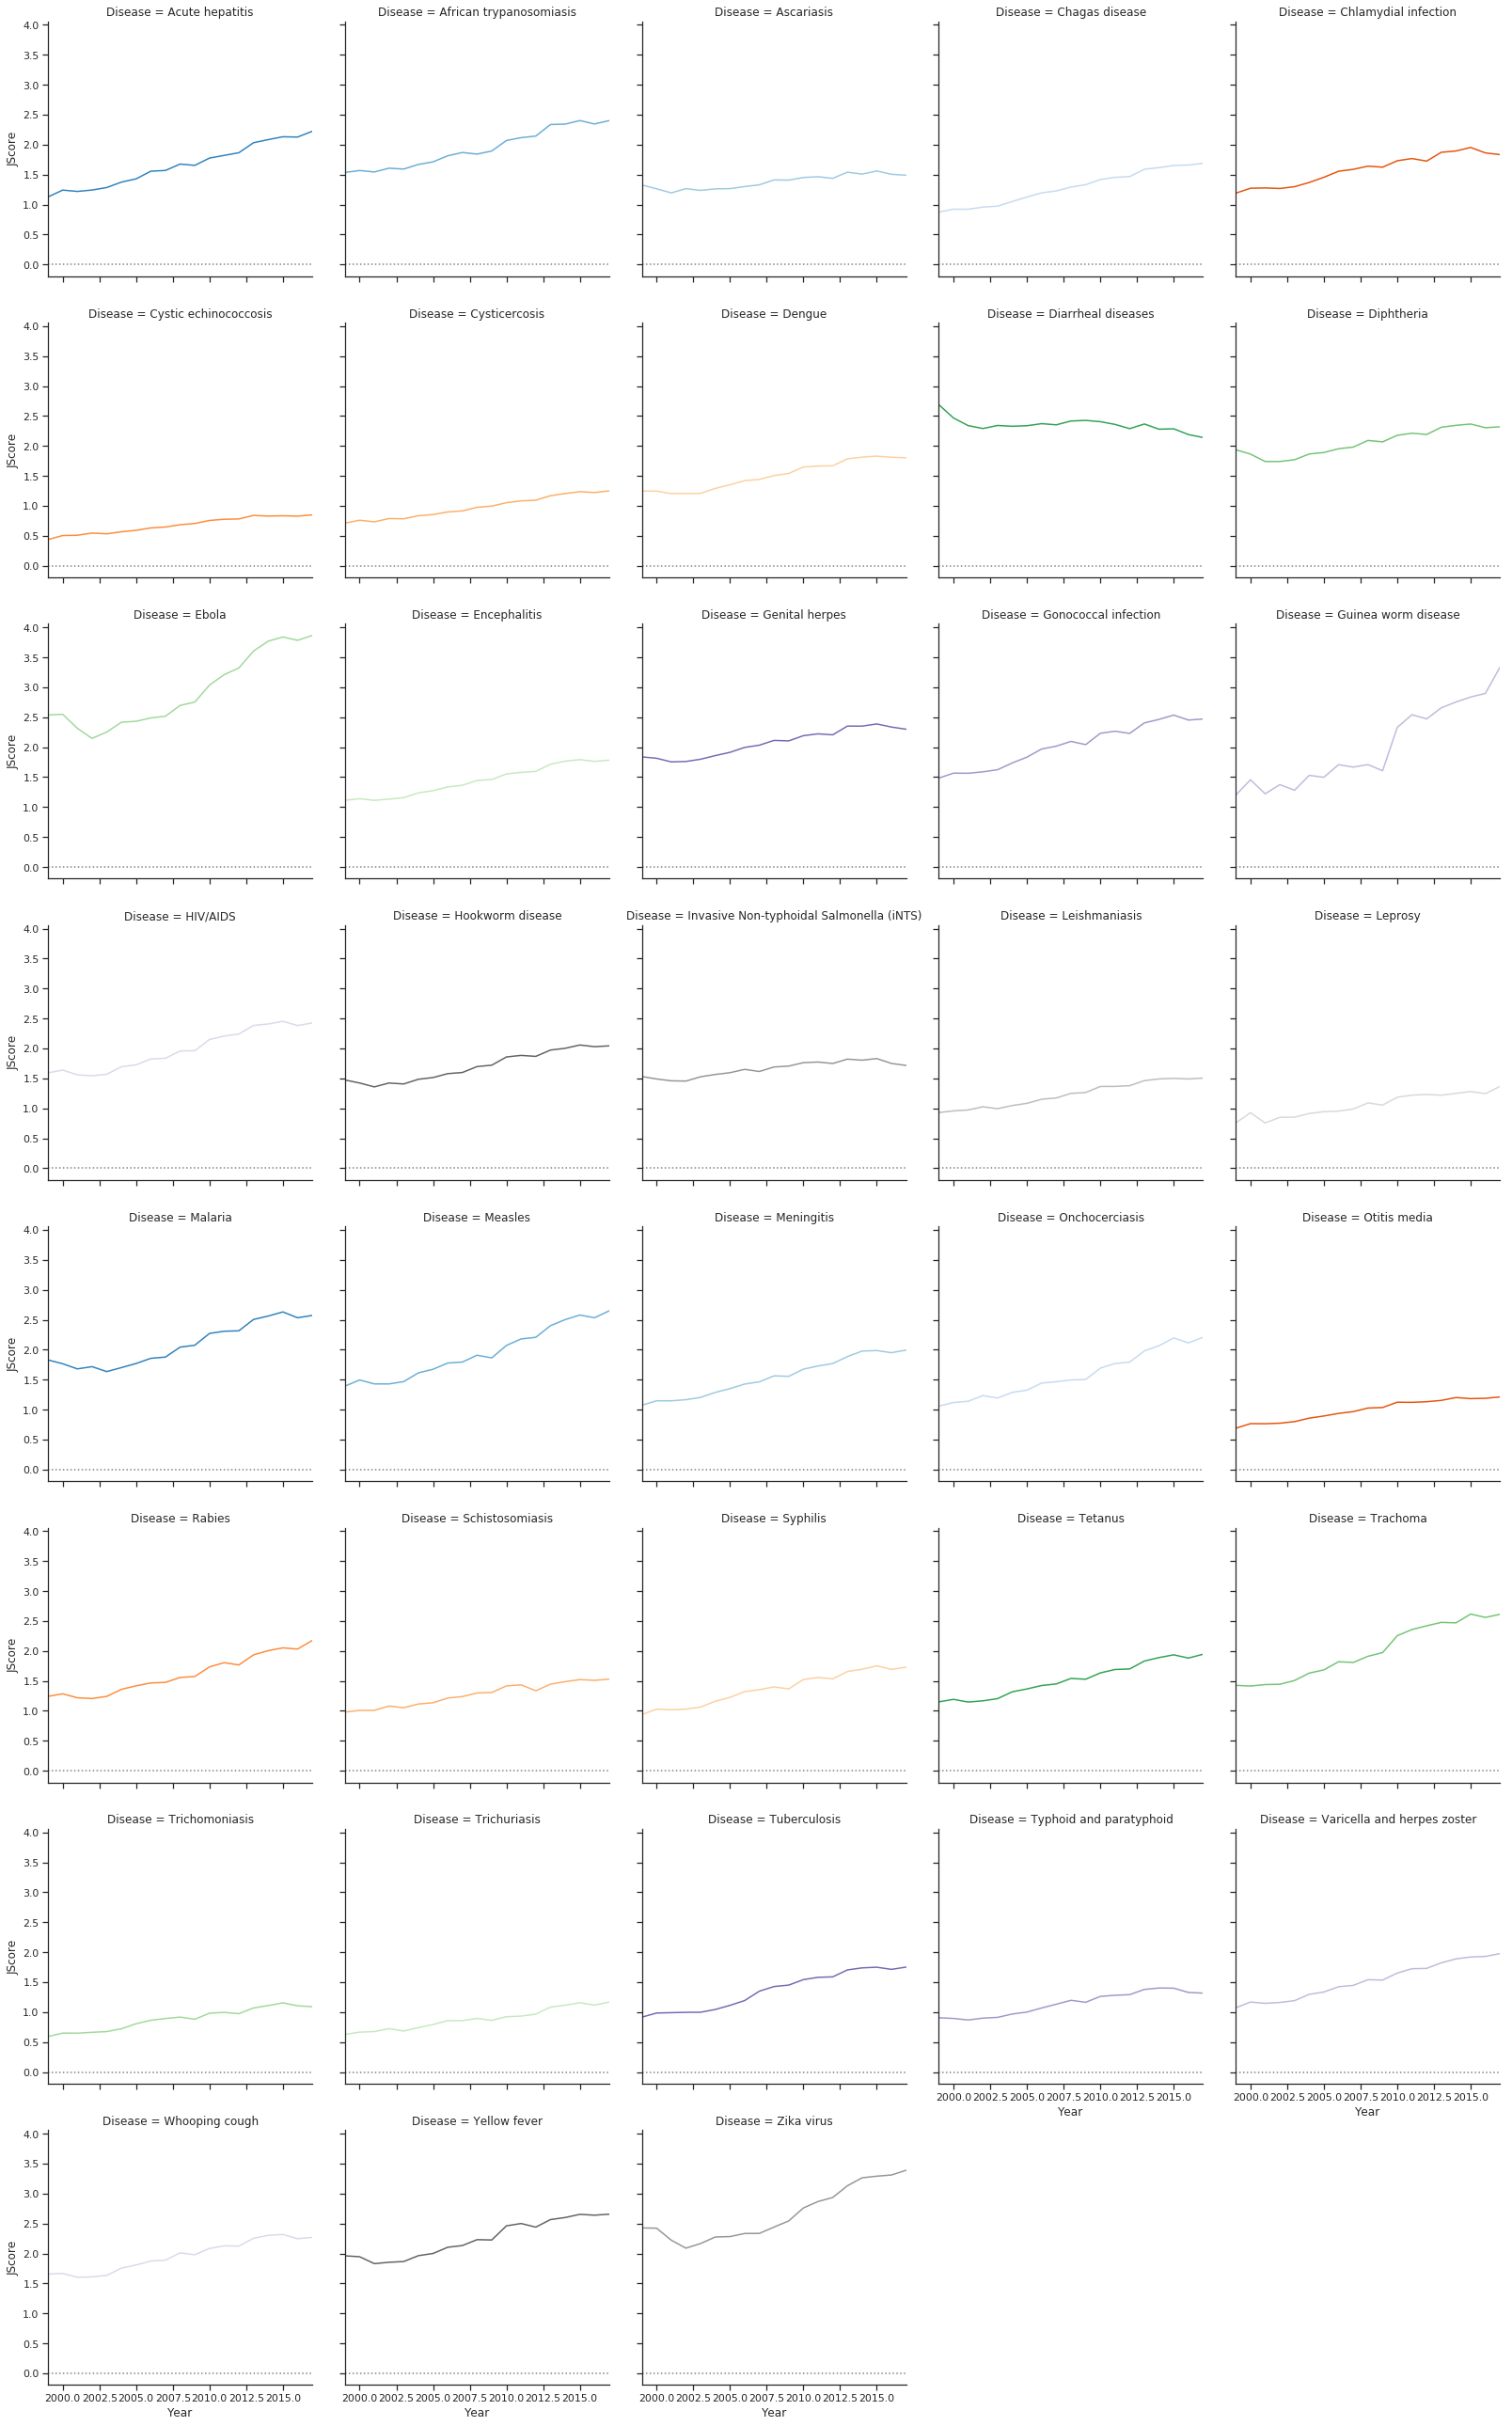

In [145]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

# Initialize a grid of plots with an Axes for each walk
grid = sns.FacetGrid(journal_disease_year_score.to_dataframe(), col="Disease", hue="Disease", palette="tab20c",
                     col_wrap=5, height=4.5 )

# Draw a horizontal line to show the starting point
grid.map(plt.axhline, y=0, ls=":", c=".5")

# Draw a line plot to show the trajectory of each random walk
grid.map(plt.plot, "Year", "JScore")

# Adjust the tick positions and labels
grid.set(xlim=(1999, 2017))

# Adjust the arrangement of the plots
grid.fig.tight_layout(w_pad=1)

### Top Papers by Venue

In [141]:
pubmed_sjr.head(1)

Columns:
	Rank	int
	Sourceid	int
	Title	str
	Type	str
	SJR	float
	SJR Best Quartile	str
	H index	int
	Total Docs.	int
	Total Docs. (3years)	int
	Total Refs.	int
	Total Cites (3years)	int
	Citable Docs. (3years)	int
	Cites / Doc. (2years)	str
	Ref. / Doc.	str
	Country	str
	Publisher	str
	Categories	str
	Year	int
	ISSN	str
	paper id	str
	sources	list
	title	str
	venue	str
	journalName	str
	inCitations	dict
	authors	list
	Normalized paper title	str
	id	int
	disease	str
	pmid	str
	issn_linking	str
	Categories Clean	list

Rows: 1

Data:
+------+----------+----------+---------+-------------------+-------------------+
| Rank | Sourceid |  Title   |   Type  |        SJR        | SJR Best Quartile |
+------+----------+----------+---------+-------------------+-------------------+
|  7   |  20798   | Immunity | journal | 22.29800033569336 |         Q1        |
+------+----------+----------+---------+-------------------+-------------------+
+---------+-------------+----------------------+-------------+----------------------+
| H index | Total Docs. | Total Docs. (3years) | Total Refs. | Total Cites (3years) |
+---------+-------------+----------------------+-------------+----------------------+
|   342   |     155     |         447          |     7759    |         9185         |
+---------+-------------+----------------------+-------------+----------------------+
+------------------------+-----------------------+-------------+---------------+
| Citable Docs. (3years) | Cites / Doc. (2years) | Ref. / Doc. |    Country    |
+------------------------+-----------------------+-------------+---------------+
|          438           |         20,38         |    50,06    | United States |
+------------------------+-----------------------+-------------+---------------+
+------------+-------------------------------+------+----------+
| Publisher  |           Categories          | Year |   ISSN   |
+------------+-------------------------------+------+----------+
| Cell Press | Immunology (Q1); Immunolog... | 1999 | 10747613 |
+------------+-------------------------------+------+----------+
+-------------------------------+-----+
|            paper id           | ... |
+-------------------------------+-----+
| 39dfe3828a810705739a0a992f... | ... |
+-------------------------------+-----+
[1 rows x 32 columns]

In [143]:
pubmed_sjr["n_citation"] = pubmed_sjr["inCitations"].apply(lambda x: len(x))

In [144]:
top_papers = pubmed_sjr.groupby("disease", operations={"Citations": agg.MAX("n_citation"), "venue":agg.ARGMAX("n_citation","venue"), "journalName":agg.ARGMAX("n_citation","journalName"), "title":agg.ARGMAX("n_citation","title")})

In [151]:
top_papers.sort("Citations", False).save("output/Journals/most_cited_papaers.csv")

### Disease Citaion Year

In [153]:
citations_year = pubmed_sjr.groupby(["Year"], operations={"Total Citaions": agg.SUM("n_citation")})

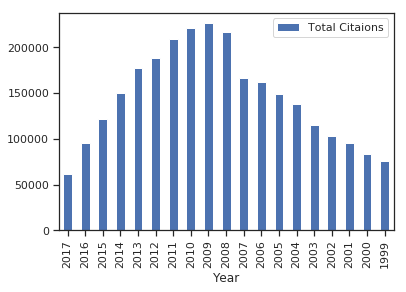

In [155]:
citations_year[(citations_year["Year"]>1990)& (citations_year["Year"]<2019)].sort("Year",False).to_dataframe().plot(kind="bar",x="Year")

In [43]:
disease_citations_year = pubmed_sjr.groupby(["disease","year"], operations={"Citaions": agg.SUM("n_citation"),"Average Citaions": agg.AVG("n_citation")})

In [44]:
disease_citations_year = disease_citations_year.join(citations_year)

In [45]:
disease_citations_year["Ciations Norm"] = disease_citations_year["Citaions"]/disease_citations_year["Total Citaions"]

In [46]:
disease_citations_year

id,year,Citaions,Average Citaions,Total Citaions,Ciations Norm
26,1863,0.0,0.0,1.0,0.0
32,1948,37.0,0.13653136531365315,251.0,0.14741035856573706
37,1918,2.0,0.10526315789473684,86.0,0.023255813953488372
4,1939,0.0,0.0,201.0,0.0
34,1890,1.0,0.02941176470588236,10.0,0.1
27,1888,0.0,0.0,13.0,0.0
17,2019,0.0,0.0,0.0,nan
2,2004,2850.0,29.687500000000018,469858.0,0.00606566239161619
22,1860,0.0,0.0,1.0,0.0
23,1956,1.0,0.02631578947368421,1659.0,0.0006027727546714888


In [47]:
output_folder = "output"
temp_folder = "temp"

os.makedirs(output_folder, exist_ok=True)
des = list(get_d(disease_citations_year.to_dataframe(), diseases_id, "year"))
for i, curr_f in enumerate(tqdm(chunks(des, 9), total=((len(des) // 9)+1))):
    draw_probas_graph(curr_f, str(i), temp_folder,{"Average Citaions":"Average Citaions","Ciations Norm":"Ciations Norm"}, "year")
create_pdf(temp_folder,f"{output_folder}/disease_citations_year2")

100%|██████████| 5/5 [00:05<00:00,  1.04s/it]


<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

<Figure size 1008x1008 with 0 Axes>

### Add Citaion by Year (Calculate how many citaions added a year)

In [156]:
pubmed_sjr.head(1)

Columns:
	Rank	int
	Sourceid	int
	Title	str
	Type	str
	SJR	float
	SJR Best Quartile	str
	H index	int
	Total Docs.	int
	Total Docs. (3years)	int
	Total Refs.	int
	Total Cites (3years)	int
	Citable Docs. (3years)	int
	Cites / Doc. (2years)	str
	Ref. / Doc.	str
	Country	str
	Publisher	str
	Categories	str
	Year	int
	ISSN	str
	paper id	str
	sources	list
	title	str
	venue	str
	journalName	str
	inCitations	dict
	authors	list
	Normalized paper title	str
	id	int
	disease	str
	pmid	str
	issn_linking	str
	Categories Clean	list
	n_citation	int

Rows: 1

Data:
+------+----------+----------+---------+-------------------+-------------------+
| Rank | Sourceid |  Title   |   Type  |        SJR        | SJR Best Quartile |
+------+----------+----------+---------+-------------------+-------------------+
|  7   |  20798   | Immunity | journal | 22.29800033569336 |         Q1        |
+------+----------+----------+---------+-------------------+-------------------+
+---------+-------------+----------------------+-------------+----------------------+
| H index | Total Docs. | Total Docs. (3years) | Total Refs. | Total Cites (3years) |
+---------+-------------+----------------------+-------------+----------------------+
|   342   |     155     |         447          |     7759    |         9185         |
+---------+-------------+----------------------+-------------+----------------------+
+------------------------+-----------------------+-------------+---------------+
| Citable Docs. (3years) | Cites / Doc. (2years) | Ref. / Doc. |    Country    |
+------------------------+-----------------------+-------------+---------------+
|          438           |         20,38         |    50,06    | United States |
+------------------------+-----------------------+-------------+---------------+
+------------+-------------------------------+------+----------+
| Publisher  |           Categories          | Year |   ISSN   |
+------------+-------------------------------+------+----------+
| Cell Press | Immunology (Q1); Immunolog... | 1999 | 10747613 |
+------------+-------------------------------+------+----------+
+-------------------------------+-----+
|            paper id           | ... |
+-------------------------------+-----+
| 39dfe3828a810705739a0a992f... | ... |
+-------------------------------+-----+
[1 rows x 33 columns]

### General Publication/Ciation

In [157]:
pub_cite = pubmed_sjr.groupby(["disease"], {"count": agg.COUNT(),"n_citation": agg.SUM("n_citation"), "avg_citation": agg.AVG("n_citation")})

In [158]:
pub_cite.sort("disease")[-10:]

disease,count,n_citation,avg_citation
Yersiniosis,6,179,29.833333333333332
Zika,735,24828,33.77959183673469
Zygomycosis,73,3463,47.438356164383535
avian influenza,998,21023,21.065130260521045
chlorellosis,70,1208,17.257142857142856
cholangitis,71,878,12.36619718309859
"hand, foot and mouthdisease ...",8,177,22.125
ilheus virus,3,20,6.666666666666667
norovirus,806,17755,22.028535980148902
ozena,7,73,10.428571428571429


In [159]:
pub_cite.save("output/Journals/pub_cite.csv","csv")

### TOP Journals By Disease 

In [160]:
top_journals = pubmed_sjr.groupby(["ISSN", "disease"], {"venue":agg.SELECT_ONE("venue") ,"count": agg.COUNT(),"n_citation": agg.SUM("n_citation"), "avg_citation": agg.AVG("n_citation")})

In [161]:
top_journals

ISSN,disease,venue,count,n_citation,avg_citation
00222615,Conjunctivitis,Journal of medicalmicrobiology ...,2,7,3.5
19313128,Chikungunya,Cell host & microbe,1,27,27.0
14712334,Diphtheria,BMC Infectious Diseases,5,35,7.0
00221317,Phleboviruses,The Journal of generalvirology ...,1,2,2.0
19352727,Conjunctivitis,PLoS neglected tropicaldiseases ...,1,0,0.0
18631959,Kyasanur Forest disease,Zoonoses and publichealth ...,1,3,3.0
13693786,Brain abscess,Medical mycology,4,64,16.0
11951982,ozena,Journal of travelmedicine ...,1,2,2.0
15590631,Conjunctivitis,Journal of ExposureScience and Environme ...,1,1,1.0
00951137,Ebola,Journal of clinicalmicrobiology ...,10,365,36.5


In [163]:
top_journals.dropna().sort('n_citation',ascending=False).save("output/Journals/top_journals_diseases.csv", "csv")

### TOP Journals By Ciations 

In [164]:
top_citaions = pubmed_sjr.dropna("disease").groupby(["ISSN"], {"Venue":agg.SELECT_ONE("venue"),"n_citation": agg.SUM("n_citation"), "avg_citation": agg.AVG("n_citation"),"count":agg.COUNT()})

In [165]:
top_citaions = top_citaions[(top_citaions["ISSN"]!=None) &(top_citaions["count"]> 20)]

In [167]:
top_citaions.sort('n_citation',ascending=False).save("output/Journals/popular_journals_citations.csv","csv")

In [171]:
top_citaions.sort("avg_citation",ascending=False)

ISSN,Venue,n_citation,avg_citation,count
08938512,Clinical microbiologyreviews ...,34347,177.96373056994827,193
14741733,Nature Reviews Immunology,10518,169.64516129032256,62
10575987,MMWR. Recommendations andreports : Morbidity and ...,15935,139.78070175438592,114
15292908,Nature Immunology,12204,137.12359550561803,89
10747613,Immunity,10553,101.47115384615387,104
01686445,FEMS microbiology reviews,3305,97.20588235294119,34
00221007,The Journal ofexperimental medicine ...,45434,89.79051383399207,506
19313128,Cell host & microbe,12373,68.35911602209947,181
15458636,Morbidity and mortalityweekly report. ...,1713,63.44444444444445,27
14733099,The Lancet. Infectiousdiseases ...,45289,58.51291989664083,774
